## 🎯 Задание для самостоятельной работы (ДЗ 7)

1. Загрузите датасет **Breast Cancer** (`sklearn.datasets.load_breast_cancer`).
2. Обучите `RandomForestClassifier` на исходных 30 признаках и замерьте accuracy.
3. Примените `PCA(n_components=0.95)` (сохранив 95% дисперсии).
4. Обучите ту же модель на сжатых признаках. Упало ли качество? Насколько сильно?
5. Попробуйте визуализировать данные через `UMAP` и раскрасить по целевому классу (malignant/benign).

*Цель: понять, что понижение размерности может как ускорять модель, так и немного снижать точность, и научиться находить баланс.*

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import umap

plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)

In [47]:
# --- 1. Загрузка датасета ---
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
target_names = data.target_names

print(f"Размерность X: {X.shape}")
print(f"Классы: {target_names}, распределение: {np.bincount(y)}")
print(f"Признаки: {len(feature_names)}")

Размерность X: (569, 30)
Классы: ['malignant' 'benign'], распределение: [212 357]
Признаки: 30


In [48]:
# --- 2. Обучаем RandomForestClassifier на 30 признаках ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Масштабирование
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train_scaled, y_train)

y_pred_RF = rf.predict(X_test_scaled)
acc_RF = accuracy_score(y_test, y_pred_RF)

print(f"Рандомный лес на {len(feature_names)} признаках")
print(f"Accuracy: {acc_RF:.4f}")

Рандомный лес на 30 признаках
Accuracy: 0.9561


In [49]:
# --- 3. PCA, сохраняющий 95% дисперсии ---
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca  = pca.transform(X_test_scaled)   # transform только, не fit!

n_comp = pca.n_components_
print(f"Исходных признаков: {len(feature_names)}")
print(f"Компонент после PCA(0.95): {n_comp}")
print(f"Сохранено дисперсии: {pca.explained_variance_ratio_.sum():.4f}")

Исходных признаков: 30
Компонент после PCA(0.95): 10
Сохранено дисперсии: 0.9527


In [50]:
# --- 4. RandomForestClassifier на сжатых данных PCA ---
rf_pca = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_pca.fit(X_train_pca, y_train)

y_pred_pca = rf_pca.predict(X_test_pca)
acc_rf_pca = accuracy_score(y_test, y_pred_pca)

print(f"[PCA] {n_comp} компонент (95% дисперсии)")
print(f"Accuracy PCA: {acc_rf_pca:.4f}\nAccuracy RF: {acc_RF:.4f}")

if acc_rf_pca > acc_RF:
    print("Обучение на сжатых данных оказалось более качественным, чем на полных.")
elif acc_rf_pca < acc_RF:
    print("Обучение на полных данных оказалось более качественным, чем на сжатых.")
else: print("Качество обучения не изменилось как при полных данных, так и при сжатых.")

[PCA] 10 компонент (95% дисперсии)
Accuracy PCA: 0.9386
Accuracy RF: 0.9561
Обучение на полных данных оказалось более качественным, чем на сжатых.


C:\Users\Daniil\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


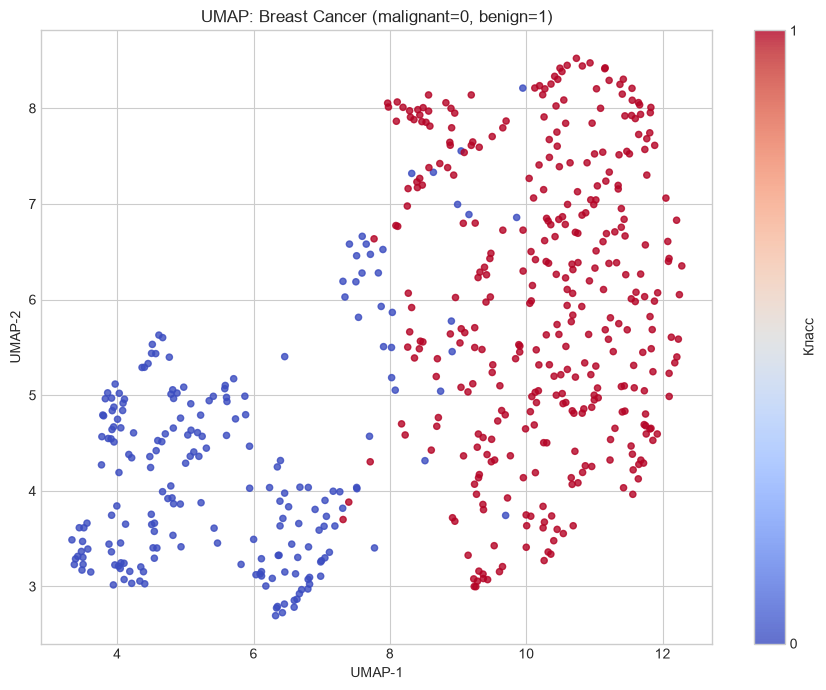

In [51]:
# --- 5. UMAP Визуализация ---
X_all_scaled = scaler.transform(X)

reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42, compatibility_layout=True) # Предупреждение об использовании 1 ядра из-за использования <<random_state=42>>
X_umap = reducer.fit_transform(X_all_scaled)

plt.figure(figsize=(9, 7))
scatter = plt.scatter(X_umap[:, 0], X_umap[:, 1], c=y, cmap="coolwarm", s=20, alpha=0.8)
plt.colorbar(scatter, ticks=[0, 1], label="Класс")
plt.title("UMAP: Breast Cancer (malignant=0, benign=1)")
plt.xlabel("UMAP-1"); plt.ylabel("UMAP-2")
plt.tight_layout(); plt.show()